In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Current folder:", Path.cwd())

dataset_name = "WEDA-FALL-main"

possible_paths = [
    Path("data/raw") / dataset_name,
    Path("../data/raw") / dataset_name,
]

DATASET_DIR = None

for path in possible_paths:
    if path.exists():
        DATASET_DIR = path
        break

if DATASET_DIR is None:
    raise FileNotFoundError("WEDA-FALL folder not found. Please check your data/raw folder.")

FREQ_DIR = DATASET_DIR / "dataset" / "50Hz"

if not FREQ_DIR.exists():
    raise FileNotFoundError("WEDA-FALL 50Hz folder not found.")

print("Dataset found:", DATASET_DIR)
print("Using sensor folder:", FREQ_DIR)

TensorFlow version: 2.21.0
Current folder: /Users/zichen/fall_detection_project/notebooks
Dataset found: ../data/raw/WEDA-FALL-main
Using sensor folder: ../data/raw/WEDA-FALL-main/dataset/50Hz


In [2]:
# Normal daily activities
ADL_CODES = {
    "D01",  # walking
    "D02",  # jogging
    "D03",  # walking up and downstairs
    "D04",  # sitting on chair, wait, and get up
    "D05",  # attempt to get up and collapse into chair
    "D06",  # crouching, tie shoes, and get up
    "D07",  # stumble while walking
    "D08",  # gently jump without falling
    "D09",  # hit table with hand
    "D10",  # clapping hands
    "D11",  # opening and closing door
}

# Fall activities
FALL_CODES = {
    "F01",  # fall forward while walking, slip
    "F02",  # lateral fall while walking, slip
    "F03",  # fall backward while walking, slip
    "F04",  # fall forward while walking, trip
    "F05",  # fall backward when trying to sit down
    "F06",  # fall forward while sitting
    "F07",  # fall backward while sitting
    "F08",  # lateral fall while sitting
}

WINDOW_SIZE = 128
STEP_SIZE = 64
SAMPLING_RATE = 50

# WEDA-FALL provides manual fall start/end times. Keeping this True labels only
# windows that overlap the real fall interval as fall.
USE_FALL_TIMESTAMPS = True
MIN_FALL_OVERLAP = 0.30

print("Labels ready")

Labels ready


In [3]:
def read_wedafall_sensor_file(file_path):
    df = pd.read_csv(file_path)

    if df.empty or df.shape[1] < 4:
        return pd.DataFrame(columns=["timestamp", "x", "y", "z"])

    df = df.iloc[:, :4].copy()
    df.columns = ["timestamp", "x", "y", "z"]

    for col in ["timestamp", "x", "y", "z"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna().reset_index(drop=True)
    return df


def parse_wedafall_filename(file_path):
    sensor_map = {
        "accel": "acc",
        "gyro": "gyro",
    }

    match = re.match(r"U(\d+)_R(\d+)_(accel|gyro)\.csv$", file_path.name)

    if match is None:
        return None

    subject, trial, raw_sensor = match.groups()
    activity = file_path.parent.name
    sensor = sensor_map[raw_sensor]

    if activity not in ADL_CODES and activity not in FALL_CODES:
        return None

    return activity, sensor, subject, trial


samples = {}

for file_path in FREQ_DIR.rglob("*.csv"):
    parsed = parse_wedafall_filename(file_path)

    if parsed is None:
        continue

    activity, sensor, subject, trial = parsed
    key = (activity, subject, trial)

    if key not in samples:
        samples[key] = {}

    samples[key][sensor] = file_path

print("Total sample groups found:", len(samples))

Total sample groups found: 969


In [4]:
fall_intervals = {}
timestamps_path = DATASET_DIR / "dataset" / "fall_timestamps.csv"

if USE_FALL_TIMESTAMPS and timestamps_path.exists():
    fall_times_df = pd.read_csv(timestamps_path, encoding="utf-8-sig")

    for _, row in fall_times_df.iterrows():
        filename = str(row["filename"])
        start_time = float(row["start_time"])
        end_time = float(row["end_time"])
        fall_intervals[filename] = (start_time, end_time)

print("Fall timestamp intervals loaded:", len(fall_intervals))


def window_has_fall(activity, subject, trial, start_time, end_time):
    if activity not in FALL_CODES:
        return False

    if not USE_FALL_TIMESTAMPS:
        return True

    interval_key = f"{activity}/U{int(subject):02d}_R{int(trial):02d}"

    if interval_key not in fall_intervals:
        return True

    fall_start, fall_end = fall_intervals[interval_key]
    overlap = max(0.0, min(end_time, fall_end) - max(start_time, fall_start))
    window_duration = max(end_time - start_time, 1e-6)

    return (overlap / window_duration) >= MIN_FALL_OVERLAP

Fall timestamp intervals loaded: 350


In [5]:
X = []
y = []
subjects = []

for key, sensor_files in samples.items():
    activity, subject, trial = key

    # Need both accelerometer and gyroscope
    if "acc" not in sensor_files or "gyro" not in sensor_files:
        continue

    acc_df = read_wedafall_sensor_file(sensor_files["acc"])
    gyro_df = read_wedafall_sensor_file(sensor_files["gyro"])

    min_len = min(len(acc_df), len(gyro_df))

    if min_len < WINDOW_SIZE:
        continue

    acc_values = acc_df[["x", "y", "z"]].values[:min_len]
    gyro_values = gyro_df[["x", "y", "z"]].values[:min_len]
    timestamps = acc_df["timestamp"].values[:min_len]

    # Combine acc + gyro = 6 features
    combined = np.concatenate([acc_values, gyro_values], axis=1)

    for start in range(0, len(combined) - WINDOW_SIZE + 1, STEP_SIZE):
        end = start + WINDOW_SIZE
        start_time = float(timestamps[start])
        end_time = float(timestamps[end - 1])

        if activity in ADL_CODES:
            label = 0
        elif window_has_fall(activity, subject, trial, start_time, end_time):
            label = 1
        elif USE_FALL_TIMESTAMPS:
            label = 0
        else:
            continue

        X.append(combined[start:end])
        y.append(label)
        subjects.append(subject)

X = np.array(X)
y = np.array(y)
subjects = np.array(subjects)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Normal windows:", np.sum(y == 0))
print("Fall windows:", np.sum(y == 1))

if X.size == 0 or len(np.unique(y)) < 2:
    raise ValueError("Not enough wearable windows from both classes. Check dataset path and labels.")

X shape: (7469, 128, 6)
y shape: (7469,)
Normal windows: 6504
Fall windows: 965


In [6]:
splitter = GroupShuffleSplit(
    n_splits=50,
    test_size=0.2,
    random_state=42
)

train_idx = None
test_idx = None

for candidate_train_idx, candidate_test_idx in splitter.split(X, y, groups=subjects):
    y_train_check = y[candidate_train_idx]
    y_test_check = y[candidate_test_idx]

    if len(np.unique(y_train_check)) == 2 and len(np.unique(y_test_check)) == 2:
        train_idx = candidate_train_idx
        test_idx = candidate_test_idx
        break

if train_idx is None or test_idx is None:
    raise ValueError("Could not make a subject split with both normal and fall classes.")

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Train windows:", X_train.shape[0])
print("Test windows:", X_test.shape[0])
print("Train normal:", np.sum(y_train == 0))
print("Train fall:", np.sum(y_train == 1))
print("Test normal:", np.sum(y_test == 0))
print("Test fall:", np.sum(y_test == 1))

# Normalize data
scaler = StandardScaler()

X_train_2d = X_train.reshape(-1, X_train.shape[-1])
X_test_2d = X_test.reshape(-1, X_test.shape[-1])

scaler.fit(X_train_2d)

X_train_scaled = scaler.transform(X_train_2d).reshape(X_train.shape)
X_test_scaled = scaler.transform(X_test_2d).reshape(X_test.shape)

print("Data normalization completed")

Train windows: 5959
Test windows: 1510
Train normal: 5200
Train fall: 759
Test normal: 1304
Test fall: 206
Data normalization completed


In [7]:
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight = {
    0: weights[0],
    1: weights[1]
}

print("Class weights:", class_weight)

model = models.Sequential([
    layers.Input(shape=(WINDOW_SIZE, 6)),

    layers.Conv1D(32, kernel_size=5, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(64, kernel_size=5, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=2),

    layers.GlobalAveragePooling1D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    class_weight=class_weight,
    verbose=1
)

Class weights: {0: np.float64(0.5729807692307692), 1: np.float64(3.9255599472990776)}
Epoch 1/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8213 - loss: 0.4133 - precision: 0.3178 - recall: 0.7643 - val_accuracy: 0.7223 - val_loss: 0.6701 - val_precision: 0.4709 - val_recall: 0.6885
Epoch 2/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9071 - loss: 0.2654 - precision: 0.5075 - recall: 0.8172 - val_accuracy: 0.7441 - val_loss: 0.7438 - val_precision: 0.5000 - val_recall: 0.7279
Epoch 3/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9213 - loss: 0.2292 - precision: 0.5587 - recall: 0.8282 - val_accuracy: 0.7777 - val_loss: 0.6163 - val_precision: 0.5541 - val_recall: 0.6721
Epoch 4/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9213 - loss: 0.2160 - precision: 0.5575 - recall: 0.8436 - val_accuracy: 0.7651 - val_loss: 0.6457 - val_precision: 0.5276 - val_recall: 0.7836
Epoch 5/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9331 - 

In [8]:
# Predict fall probability
y_prob = model.predict(X_test_scaled).ravel()

# Selected threshold
BEST_THRESHOLD = 0.40

# Convert probability to class label
y_pred = (y_prob >= BEST_THRESHOLD).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
fall_precision = precision_score(y_test, y_pred, zero_division=0)
fall_recall = recall_score(y_test, y_pred, zero_division=0)
fall_f1 = f1_score(y_test, y_pred, zero_division=0)

print("===== FINAL WEDA-FALL CNN MODEL RESULT =====")
print(f"Threshold Used : {BEST_THRESHOLD}")
print(f"Accuracy       : {accuracy * 100:.2f}%")
print(f"Fall Precision : {fall_precision * 100:.2f}%")
print(f"Fall Recall    : {fall_recall * 100:.2f}%")
print(f"Fall F1-score  : {fall_f1 * 100:.2f}%")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Normal", "Actual Fall"],
    columns=["Predicted Normal", "Predicted Fall"]
)

print("\nConfusion Matrix:")
print(cm_df)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Fall"],
    zero_division=0
))

48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
===== FINAL WEDA-FALL CNN MODEL RESULT =====
Threshold Used : 0.4
Accuracy       : 88.68%
Fall Precision : 55.63%
Fall Recall    : 83.98%
Fall F1-score  : 66.92%

Confusion Matrix:
               Predicted Normal  Predicted Fall
Actual Normal              1166             138
Actual Fall                  33             173

Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.89      0.93      1304
        Fall       0.56      0.84      0.67       206

    accuracy                           0.89      1510
   macro avg       0.76      0.87      0.80      1510
weighted avg       0.92      0.89      0.90      1510



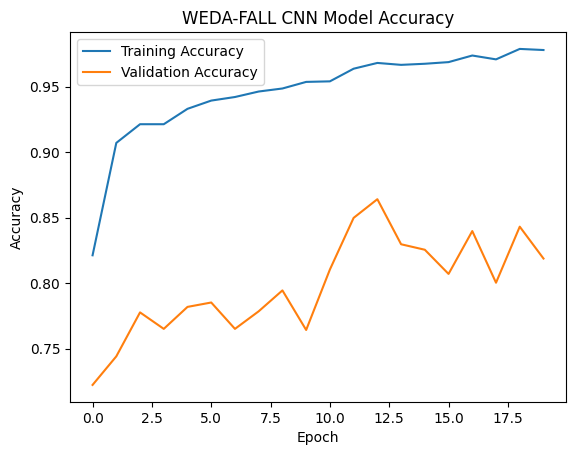

In [9]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("WEDA-FALL CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [10]:
import pickle

save_dir = Path("../saved_model")

if not save_dir.exists():
    save_dir = Path("saved_model")

save_dir.mkdir(parents=True, exist_ok=True)

model_path = save_dir / "wedafall_cnn.keras"
scaler_path = save_dir / "wedafall_scaler.pkl"

model.save(model_path)

with open(scaler_path, "wb") as f:
    pickle.dump(scaler, f)

print("Saved wearable model:", model_path)
print("Saved wearable scaler:", scaler_path)

Saved wearable model: ../saved_model/wedafall_cnn.keras
Saved wearable scaler: ../saved_model/wedafall_scaler.pkl
